# SCAF tutorial

SCAF fits a linear outcome model and learns which treatments can share an effect.

An individualized treatment rule (ITR) maps a person's pretreatment features
to a treatment recommendation. For each person we observe the outcome under
the treatment they received. The model uses data from other people to estimate
the outcomes under the alternatives. When many treatments have few observations
each, pooling treatments with similar effects can make those estimates more
precise. Here, a treatment group is a set of treatments that share an estimated
effect.

Install the wheel with the `[plot]` extra and install JupyterLab and pandas in the same environment
using the [README](../README.md#install). Open this notebook with that environment's Python
kernel, then choose **Kernel → Restart Kernel and Run All Cells**. The saved outputs show
one CPU run. The last digits can vary across environments.

Two observed CPU runs took about 20 and 48 seconds. Runtime depends on
the machine, data, and fitting settings.

## Before you start

You should be comfortable with linear regression, cross-validation, and basic NumPy arrays and pandas DataFrames.

## What you will learn

- Fit and interpret SCAF's common effect, initializer, and fused treatment groups.
- Choose penalties with cross-validated MSE or BIC and inspect the fusion path.
- Predict a treatment for new people and evaluate the policy on held-out data.
- Prepare your own data and diagnose common fitting and evaluation problems.

## Contents

- [Part I · Core workflow](#scaf-core)
  - [1. Model and data](#scaf-data)
  - [2. Hold back test data](#scaf-split)
  - [3. Read the fitting stages](#scaf-fit)
  - [4. Tune the penalties](#scaf-tune)
  - [5. Plot the fusion path](#scaf-path)
  - [6. Predict for new people](#scaf-predict)
  - [7. Evaluate recommendations](#scaf-evaluate)
- [Part II · Advanced topics](#scaf-advanced)
  - [8. Penalty scaling and grids](#scaf-grids)
  - [9. Compare CV MSE and BIC](#scaf-compare)
  - [10. Noisy outcomes](#scaf-noise)
  - [11. Outcome units](#scaf-units)
  - [12. Your own data](#scaf-own-data)
- [Troubleshooting](#scaf-troubleshooting)
- [Recap and next steps](#scaf-recap)

<a id="scaf-core"></a>

# Part I. Core workflow

<a id="scaf-data"></a>

## 1. Understand the model and generate the data

For a person with covariates $X_i$ who received treatment $A_i$, SCAF models
$Y_i = m(X_i) + \tilde X_i^\top\beta_{A_i} + \varepsilon_i$.
Here $m$ is the common linear main effect, $\tilde X_i$ prepends a 1 for the
intercept, and $\beta_{A_i}$ is the treatment's residual coefficient vector.
A treatment group shares one residual coefficient vector. In section 3 you
will inspect the common regression, the group-lasso initializer, and the
fused coefficients in that order.

### Generate the data

Each row represents one person. `X` contains four features measured before treatment,
`treatment` is the treatment the person received, and `y` is the observed outcome.
Larger outcomes are better here. Treatments A and B have the same true effect, as do
C and D. The effect changes sign between the two groups. Feature `x2` contributes equally
under all treatments, and `x4` is noise.

In [1]:
%matplotlib inline
import numpy as np
from matplotlib import pyplot as plt

from itr_methods import SCAF

demo_arms = np.array(["A", "B", "C", "D"])

def true_outcome_means(features, arms):
    direction = np.where(np.isin(arms, ["A", "B"]), 1.0, -1.0)
    contrast = 2 * features[:, 0] + features[:, 2]
    return 0.4 * features[:, 1, None] + contrast[:, None] * direction

rng = np.random.default_rng(7)
X = rng.normal(size=(240, 4))
treatment = np.tile(demo_arms, 60)
y = true_outcome_means(X, demo_arms)[np.arange(len(X)), np.searchsorted(demo_arms, treatment)]
y += rng.normal(scale=0.25, size=len(X))
feature_names = ["x1", "x2", "x3", "x4"]

print("First person's features:", dict(zip(feature_names, X[0].round(3).tolist())))
print("Treatment received:", treatment[0])
print(f"Observed outcome: {y[0]:.3f}")

First person's features: {'x1': 0.001, 'x2': 0.299, 'x3': -0.274, 'x4': -0.891}
Treatment received: A
Observed outcome: 0.312


<a id="scaf-split"></a>

## 2. Hold back a test set

Both splits contain all four treatments because the labels were assigned in a repeating
sequence. Use the training rows for tuning and fitting. Save the test outcomes for the
final evaluation.

In [2]:
X_train, y_train, treatment_train = X[:192], y[:192], treatment[:192]
X_test, y_test, treatment_test = X[192:], y[192:], treatment[192:]
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training counts:", dict(zip(*[v.tolist() for v in np.unique(treatment_train, return_counts=True)])))

Training rows: 192
Test rows: 48
Training counts: {'A': 48, 'B': 48, 'C': 48, 'D': 48}


<a id="scaf-fit"></a>

## 3. Read the three fitting stages and the treatment groups

**1. Common main effect.** Fit a single regression to all training rows to explain
the part of the outcome that does not depend on treatment. Subtract its fitted values
to obtain residuals. The intercept is the first coefficient.

**2. Group-lasso initializer.** Fit the residuals using treatment-by-feature
interactions. The initializer shrinks the coefficients for each feature as a block.
A feature whose entire block reaches zero is designated as shared in stage 3.

**3. Adaptive fusion.** Refit the residual model, estimating one coefficient per
shared feature and penalizing differences between treatment rows on the remaining
features. Adaptive weights increase as the distance between the current
coefficient rows decreases, up to a cap. The residual model predicts the
correction to the common main effect. The two fixed penalties below are
illustrative values for this data.

The cell below checks the first stage against a direct least-squares calculation,
then prints the before-and-after residual coefficients. Compare the `x1` column:
it can differ for A and B after the initializer, then matches exactly after fusion.
Group IDs label groups within this fit. Very close rows can have the same reported
group under `group_tolerance`. Exactly equal rows give equal predictions for every person.

In [3]:
first_fit = SCAF(init_lambda=20.0, fusion_lambda=0.5).fit(
    X_train, y_train, treatment=treatment_train,
)
columns = np.array(["intercept", *feature_names])
design_train = np.column_stack([np.ones(len(X_train)), X_train])
main_ols = np.linalg.lstsq(design_train, y_train, rcond=None)[0]
residual_train = y_train - design_train @ first_fit.main_effect_coef_
labels = first_fit.treatments_.tolist()

print("Stage 1 matches pooled least squares:", np.allclose(first_fit.main_effect_coef_, main_ols))
print("Common coefficients:", first_fit.main_effect_coef_.round(3).tolist())
print(f"First training residual: {residual_train[0]:.3f}")
print("Coefficient order:", columns.tolist())
print("Stage 2 shared columns:", columns[first_fit.shared_columns_].tolist())
print("Stage 2 treatment-specific columns:", columns[first_fit.contrast_columns_].tolist())
for arm, initial, fused in zip(labels, first_fit.initializer_coef_, first_fit.contrast_coef_):
    print(f"{arm}  initializer {initial.round(3).tolist()}  fused {fused.round(3).tolist()}")
print("Stage 3 group IDs:", dict(zip(labels, first_fit.group_ids_.tolist())))

for left, right in [("A", "B"), ("C", "D")]:
    left_coef = first_fit.contrast_coef_[labels.index(left)]
    right_coef = first_fit.contrast_coef_[labels.index(right)]
    print(f"{left} and {right} have exactly equal fused coefficients:",
          np.array_equal(left_coef, right_coef))

Stage 1 matches pooled least squares: True
Common coefficients: [-0.018, -0.069, 0.399, -0.017, -0.031]
First training residual: 0.179
Coefficient order: ['intercept', 'x1', 'x2', 'x3', 'x4']
Stage 2 shared columns: ['intercept', 'x2', 'x4']
Stage 2 treatment-specific columns: ['x1', 'x3']
A  initializer [0.0, 1.949, 0.0, 0.93, 0.0]  fused [0.015, 2.07, 0.05, 1.007, 0.02]
B  initializer [0.0, 1.984, 0.0, 0.899, 0.0]  fused [0.015, 2.07, 0.05, 1.007, 0.02]
C  initializer [0.0, -1.829, 0.0, -0.882, 0.0]  fused [0.015, -1.919, 0.05, -0.975, 0.02]
D  initializer [0.0, -1.798, 0.0, -0.88, 0.0]  fused [0.015, -1.919, 0.05, -0.975, 0.02]
Stage 3 group IDs: {'A': 0, 'B': 0, 'C': 1, 'D': 1}
A and B have exactly equal fused coefficients: True
C and D have exactly equal fused coefficients: True


The common main effect cancels when comparing two treatments for the
same person. Using the rounded values above, the fitted A-minus-C
coefficient on $x_1$ is $2.070-(-1.919)\approx3.99$ (true value 4).
On $x_3$ it is $1.007-(-0.975)\approx1.98$ (true value 2).
The intercept, $x_2$, and $x_4$ can have nonzero residual coefficients.
They are common corrections applied to every treatment, so they cancel
in this comparison too.

<a id="scaf-tune"></a>

## 4. Tune the two penalties

In `fit_cv()`, omit `init_lambdas` to get 15 log-spaced candidates from
$\lambda_{\max}$ down to $0.01\lambda_{\max}$. The endpoint is the smallest
initializer penalty that sets all initializer coefficients to zero.
Cross-validation is stratified by treatment.

| Parameter | Package default | Tutorial setting | Role and when to tune |
| --- | --- | --- | --- |
| `init_lambda` ($\lambda_1$) | `None`, or `0.1 * lambda_max` in a direct fit | `20.0` for the first fit, automatic grid in `fit_cv()` | Shrinks treatment interactions feature by feature. Tune it when deciding which features can share coefficients. |
| `fusion_lambda` ($\lambda_2$) | `1.0` | `0.5` for the first fit, grid below for `fit_cv()` | Penalizes differences between treatment coefficients. Widen the candidate grid when it misses useful groupings. |
| `group_tolerance` | `1e-4` | Default | Cut height for reporting groups of nearly equal coefficient rows. Use it to choose the reporting resolution. |
| `fusion_selection` | `"cv_mse"` | Compare `"cv_mse"` and `"bic"` | CV MSE targets factual prediction error. BIC balances fit and grouped model complexity. |
| `max_updates` | `5` | Default | Caps adaptive weight updates after the first fusion solve. Zero keeps the initializer's weights fixed. |
| `max_iter` | `5000` | Default | Iteration limit for the initializer and for each fusion solve. Increase it if a solver reaches the limit. |
| `tol` | `1e-7` | Default | Numerical convergence tolerance. A larger value relaxes the stopping criterion. |

First fit the grid with cross-validated MSE, then use BIC as an
alternative when a compact grouping is useful.

In [4]:
fusion_grid = [0.0, 0.5, 2.0, 10.0, 100.0]
tuning = dict(treatment=treatment_train, fusion_lambdas=fusion_grid, cv=3)
cv_model = SCAF(random_state=7).fit_cv(X_train, y_train, **tuning)
cv = cv_model.cv_results_
best_index = int(np.argmin(cv["mean_mse"]))

print(f"Full training lambda_max: {cv_model.init_lambda_max_:.3f}")
print(f"Smallest lambda_1 candidate: {cv['params'][-1]['init_lambda']:.3f}")
print(f"Selected lambda_1: {cv_model.best_params_['init_lambda']:.3f}")
print(f"Selected lambda_2: {cv_model.best_params_['fusion_lambda']:g}")
print(f"Held-out CV MSE: {cv['mean_mse'][best_index]:.3f}")

Full training lambda_max: 351.956
Smallest lambda_1 candidate: 3.520
Selected lambda_1: 94.419
Selected lambda_2: 0.5
Held-out CV MSE: 0.075


With `fusion_selection="bic"`, SCAF selects $\lambda_1$ by CV MSE at
zero fusion, then compares the $\lambda_2$ candidates on the full
training set. BIC balances the unweighted least-squares error of
the grouped design against its rank. Lower is better. The first
candidate wins a tie. See [Schwarz (1978)](https://doi.org/10.1214/aos/1176344136).

In [5]:
model = SCAF(random_state=7).fit_cv(X_train, y_train, fusion_selection="bic", **tuning)
results = model.cv_results_
print("lambda_2   rank       BIC")
for params, rank, bic in zip(results["params"], results["degrees_of_freedom"], results["bic"]):
    print(f"{params['fusion_lambda']:8g} {rank:6d} {bic:9.2f}")
print(f"Selected lambda_1: {model.best_params_['init_lambda']:.3f}")
print(f"Selected lambda_2: {model.best_params_['fusion_lambda']:g}")

lambda_2   rank       BIC
       0     11   -474.16
     0.5      7   -494.02
       2      7   -494.02
      10      7   -494.02
     100      5    309.73
Selected lambda_1: 182.295
Selected lambda_2: 0.5


CV MSE selected $\lambda_1=94.419$ jointly with $\lambda_2$. The BIC
workflow selected $\lambda_1=182.295$ by CV at $\lambda_2=0$, then
kept it fixed while tuning fusion. The two procedures can therefore
choose different initializer penalties on the same data.

The rank is the number of independent columns in the grouped
least-squares design. Here there are three shared columns and two
treatment-specific columns per group. The design has full column rank
at these grid points, so the rank is $3+4\times2=11$ with four groups,
$3+2\times2=7$ with two, and $3+1\times2=5$ with one.

<a id="scaf-path"></a>

## 5. Follow the fusion path

Refit along the same $\lambda_2$ grid using the selected $\lambda_1$. The coefficient
plot shows one treatment coefficient per line. Lines overlap when the corresponding
coefficients match. The dendrogram shows full treatment rows merging. Its height
is $\log(1+1000\lambda_2)$ at each recorded merge, and the red line indicates the
selected partition (the assignment of treatments to groups). If the path later splits a group, the tree stops before the split.
The printed table still shows the full grid.

lambda_2 =     0: {'A': 0, 'B': 1, 'C': 2, 'D': 3}
lambda_2 =   0.5: {'A': 0, 'B': 0, 'C': 1, 'D': 1}
lambda_2 =     2: {'A': 0, 'B': 0, 'C': 1, 'D': 1}
lambda_2 =    10: {'A': 0, 'B': 0, 'C': 1, 'D': 1}
lambda_2 =   100: {'A': 0, 'B': 0, 'C': 0, 'D': 0}


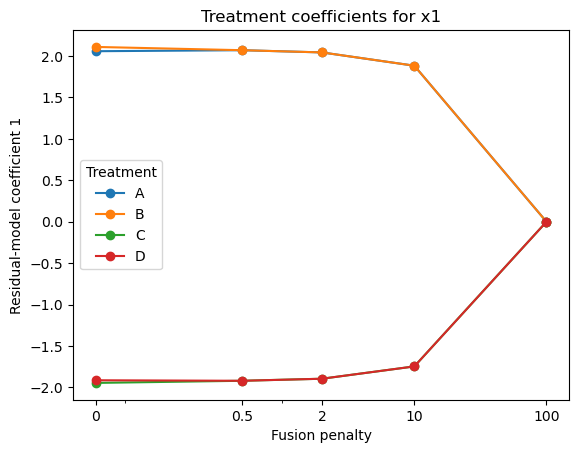

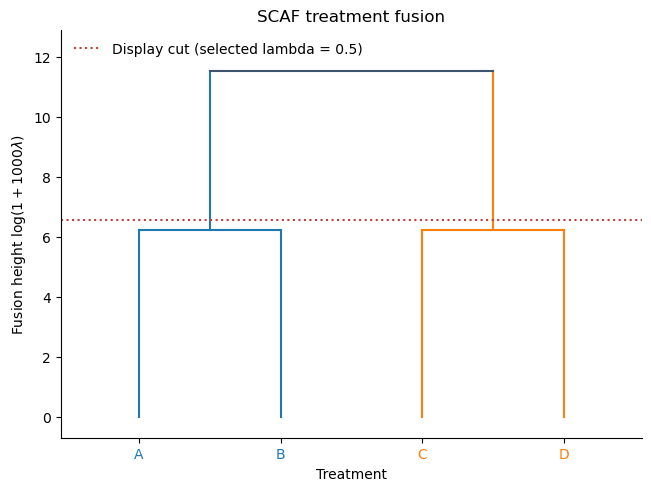

In [6]:
labels = model.treatments_.tolist()
path = model.clustering_path(
    X_train, y_train, treatment=treatment_train, fusion_lambdas=fusion_grid,
)
for penalty, ids in zip(path.fusion_lambdas, path.group_ids):
    print(f"lambda_2 = {penalty:5g}:", dict(zip(labels, ids.tolist())))

ax = path.plot(column=1)
ax.set_xscale("symlog", linthresh=0.5)
ax.set_xticks(fusion_grid, labels=[f"{value:g}" for value in fusion_grid])
ax.set_title("Treatment coefficients for x1")
plt.show()

tree = path.plot_fusion_dendrogram(
    selected_lambda=model.best_params_["fusion_lambda"], true_groups=[0, 0, 1, 1],
)
tree.set_title("SCAF treatment fusion")
plt.show()

<a id="scaf-predict"></a>

## 6. Read one recommendation and evaluate held-out predictions

`predict_outcomes` gives a predicted outcome for every treatment. `predict` recommends
the treatment with the highest prediction, choosing the first in `treatments_` when
outcomes are exactly tied. If A and B tie for first, both give the same fitted
outcome and the returned A is the tie-break. `predict_factual` gives the score for the
treatment the person actually received, so we can compare it with their observed outcome.

For the third test person, print the common and residual contributions separately
and check that their sum equals each predicted outcome. Then compute MSE on all test rows.

In [7]:
row = 2
design_row = np.r_[1.0, X_test[row]]
common = float(design_row @ model.main_effect_coef_)
residual = design_row @ model.contrast_coef_.T
scores = model.predict_outcomes(X_test)
np.testing.assert_allclose(common + residual, scores[row])
recommended = model.predict(X_test)
factual = model.predict_factual(X_test, treatment=treatment_test)

print(f"Common contribution: {common:.3f}")
print("Residual contributions:", dict(zip(labels, residual.round(3).tolist())))
print("Predicted outcomes:", dict(zip(labels, scores[row].round(3).tolist())))
print("Recommended:", recommended[row])
print("Received:", treatment_test[row])
print(f"Factual prediction: {factual[row]:.3f}")
print(f"Observed outcome: {y_test[row]:.3f}")
print(f"Test factual MSE: {np.mean((factual - y_test) ** 2):.3f}")

Common contribution: 0.202
Residual contributions: {'A': 2.792, 'B': 2.792, 'C': -2.62, 'D': -2.62}
Predicted outcomes: {'A': 2.994, 'B': 2.994, 'C': -2.418, 'D': -2.418}
Recommended: A
Received: C
Factual prediction: -2.418
Observed outcome: -2.495
Test factual MSE: 0.056


<a id="scaf-evaluate"></a>

## 7. Evaluate the recommendations

Factual MSE measures how well the model predicts observed outcomes.
**Policy value** is the average outcome we would get if we used the
recommendations. Section 5 of the SCAF paper reports empirical policy
value estimated from observed outcomes and the **group misclassification
rate**: how often the recommended treatment falls outside a truly
optimal group. A tie in the true means counts as correct.

Generate 10,000 fresh test people. These rows play no role in fitting
or model selection. Unlike the balanced repeating labels above, each
person's observed treatment here is drawn independently with
probability 1/4 for each arm. The simulator also gives the true means
for all arms. This lets us compare estimated values with their true
values, the best fixed treatment, and the individualized oracle.

In [8]:
eval_rng = np.random.default_rng(2026)
X_policy = eval_rng.normal(size=(10_000, X.shape[1]))
mean_policy = true_outcome_means(X_policy, demo_arms)
rows = np.arange(len(X_policy))

# Randomize independently for each person, with known assignment probabilities.
propensity_policy = np.full(mean_policy.shape, 1.0 / len(demo_arms))
assigned = eval_rng.integers(len(demo_arms), size=len(rows))
y_policy = mean_policy[rows, assigned] + eval_rng.normal(scale=0.25, size=len(rows))

fixed_arm = mean_policy.mean(axis=0).argmax()
print(f"Best fixed treatment ({demo_arms[fixed_arm]}) value: {mean_policy[:, fixed_arm].mean():.3f}")
print(f"Oracle policy value: {mean_policy.max(axis=1).mean():.3f}")

Best fixed treatment (C) value: 0.020
Oracle policy value: 1.775


### Estimate policy value with the SCAF paper's IPW ratio

**Self-normalized inverse probability weighting** (IPW) estimates
policy value from observed outcomes and treatment assignment
probabilities. For a deterministic rule $D$, use the weights

$$
\widehat V(D)=\frac{\sum_i w_iY_i}{\sum_i w_i},
\qquad w_i=\frac{\mathbf{1}\{A_i=D(X_i)\}}{p(A_i\mid X_i)}.
$$

The Python package's `predict()` returns the first arm in an exact tie.
To evaluate that deterministic rule, match the exact recommended arm.

The SCAF paper describes sampling an arm within the estimated optimal
group in proportion to its assignment probability. Here we take the
fitted group of the recommended arm and retain the members with the
same predicted outcome. Averaging the IPW match weight over possible
draws from this group $G(X)$ gives
$\mathbf{1}\{A_i\in G(X_i)\}/\sum_{a\in G(X_i)}p(a\mid X_i)$.
This evaluates a different policy from `predict()`. The code also
averages its misclassification rate over the possible draws.

The paper uses the IPW ratio for test evaluation in Section 5 and
proposes it for fusion tuning in Section 3. This tutorial uses IPW
only for evaluation. The package's `fit_cv()` offers CV MSE or BIC
for selecting the fusion penalty.

[Ma, Zeng, and Liu (2022), Section 5, p. 8](https://proceedings.neurips.cc/paper_files/paper/2022/file/663865ea167425c6c562cb0b6bcf76c7-Paper-Conference.pdf#page=8)
and [Section 3, p. 5](https://proceedings.neurips.cc/paper_files/paper/2022/file/663865ea167425c6c562cb0b6bcf76c7-Paper-Conference.pdf#page=5).

Resample held-out people with replacement 500 times, using the same rows
for all policies in each draw. The 2.5th and 97.5th percentiles form a 95%
bootstrap interval. These intervals describe test-sample uncertainty
conditional on the fitted policies and the assignment probabilities.
They leave out uncertainty from fitting the policies or estimating
propensities. For repeated observations, resample at the independent
unit level.

In [9]:
def bootstrap_policy_values(outcomes, weights, *, seed=2027, draws=500):
    # Each column is one fixed policy. Reuse the same rows for all policies.
    rng = np.random.default_rng(seed)
    values = np.empty((draws, weights.shape[1]))
    for draw in range(draws):
        indices = rng.integers(len(outcomes), size=len(outcomes))
        sampled_weights = weights[indices]
        total_weight = sampled_weights.sum(axis=0)
        if np.any(total_weight == 0):
            raise ValueError("A bootstrap sample has no policy matches. Check overlap.")
        values[draw] = (outcomes[indices] @ sampled_weights) / total_weight
    return values


def evaluate_policy(fitted, name):
    assert np.array_equal(fitted.treatments_, demo_arms)
    recommended = np.searchsorted(demo_arms, fitted.predict(X_policy))
    predicted = fitted.predict_outcomes(X_policy)
    recommended_mean = mean_policy[rows, recommended]
    wrong_group = mean_policy < mean_policy.max(axis=1, keepdims=True)
    arm_error = wrong_group[rows, recommended].mean()

    observed_prob = propensity_policy[rows, assigned]
    arm_match = assigned == recommended
    arm_weight = arm_match / observed_prob

    # Use members of the recommended fitted group with the same prediction.
    group_ids = fitted.group_ids_
    same_group = group_ids[None, :] == group_ids[recommended, None]
    tied = predicted == predicted[rows, recommended, None]
    members = same_group & tied
    group_prob = (members * propensity_policy).sum(axis=1)
    group_match = members[rows, assigned]
    group_weight = group_match / group_prob
    group_policy = members * propensity_policy / group_prob[:, None]
    group_value = (group_policy * mean_policy).sum(axis=1).mean()
    group_error = (group_policy * wrong_group).sum(axis=1).mean()

    print(name)
    print(f"  Group misclassification of predict() = {arm_error:.2%}")
    print(f"  True value of predict() = {recommended_mean.mean():.3f}")
    print(f"  Arm-match IPW = {np.average(y_policy, weights=arm_weight):.3f} ({arm_match.sum():,} matches)")
    print(f"  Group misclassification of the within-group policy = {group_error:.2%}")
    print(f"  True value of the within-group policy = {group_value:.3f}")
    print(f"  Group-match IPW = {np.average(y_policy, weights=group_weight):.3f} ({group_match.sum():,} matches)")

    weights = np.column_stack((arm_weight, group_weight))
    draws = bootstrap_policy_values(y_policy, weights)
    intervals = np.percentile(draws, [2.5, 97.5], axis=0).T
    for policy, (low, high) in zip(("Arm-match", "Group-match"), intervals):
        print(f"  {policy} IPW 95% bootstrap interval: [{low:.3f}, {high:.3f}]")


evaluate_policy(model, "SCAF")

SCAF
  Group misclassification of predict() = 0.08%
  True value of predict() = 1.775
  Arm-match IPW = 1.774 (2,607 matches)
  Group misclassification of the within-group policy = 0.08%
  True value of the within-group policy = 1.775
  Group-match IPW = 1.776 (5,059 matches)


  Arm-match IPW 95% bootstrap interval: [1.718, 1.829]
  Group-match IPW 95% bootstrap interval: [1.735, 1.816]


Read the group recommendation error alongside the value gap to the oracle.
An error near a true tie can cost little, while choosing the wrong group
for someone with a large treatment contrast can cost more.

<a id="scaf-advanced"></a>

# Part II. Advanced topics

<a id="scaf-grids"></a>

## 8. Inspect penalty scaling and choose a fusion grid

The objectives use sums of squared errors. Supply candidates on the
full-training-data scale. In each CV fit, SCAF multiplies the fusion
penalty and any explicitly supplied initializer penalty by the fraction
of rows used for fitting that fold. The automatic initializer grid
uses each fold's own $\lambda_{\max}$. The final fit uses the full-data
candidates. The next cell prints the fold-specific endpoints and
fusion penalties. Here each fold trains on 128 of 192 rows, so the
full-data penalty of 0.5 becomes $0.5 \times 128/192 \approx 0.333$.

You can supply candidates on the full-data scale with
`init_lambdas=[5.0, 20.0]`, or fit once with fixed penalties. The next
cell fits directly at the selected values and verifies that the outcome
predictions match.

In [10]:
print("Fold training lambda_max:", cv["fold_init_lambdas"][0].round(3).tolist())
print("Selected lambda_2 in each CV fit:", cv["fold_fusion_lambdas"][best_index].round(3).tolist())

fixed = SCAF(**model.best_params_).fit(X_train, y_train, treatment=treatment_train)
print("Fixed-penalty fit matches:", np.allclose(
    fixed.predict_outcomes(X_test), model.predict_outcomes(X_test),
))

Fold training lambda_max: [223.175, 228.612, 244.801]
Selected lambda_2 in each CV fit: [0.333, 0.333, 0.333]
Fixed-penalty fit matches: True


For a direct fit, leaving `init_lambda` unspecified uses a fixed fraction of the
training endpoint, `0.1 * lambda_max`. The same rule applies when starting a fusion path
without a prior `fit_cv()`. The public `SCAF.lambda_max()` takes the same training inputs
as `fit()` and returns the endpoint without fitting the fusion model. If you supplied
propensities for fitting, pass the same values when computing the endpoint.
Read the penalty actually used from `init_lambda_`.

Treat this default as a starting point. Section 10 tests it on noisy data and shows
how to tune only the initializer at a fixed fusion penalty.

In [11]:
endpoint = SCAF.lambda_max(X_train, y_train, treatment=treatment_train)
direct = SCAF().fit(X_train, y_train, treatment=treatment_train)
columns = np.array(["intercept", *feature_names])

print(f"Public lambda_max: {endpoint:.3f}")
print(f"Direct fit lambda_1: {direct.init_lambda_:.3f}")
print("Direct fit shared residual columns:", columns[direct.shared_columns_].tolist())

Public lambda_max: 351.956
Direct fit lambda_1: 35.196
Direct fit shared residual columns: ['intercept', 'x2', 'x4']


### Read the grid endpoints

Start with outcomes centered and scaled using training data and use
zero plus a log-spaced grid of positive $\lambda_2$ candidates. With
zero penalty the fit imposes no fusion, so distinct estimates will
typically appear as separate treatments. A large enough endpoint
should merge all treatments on this example. Inspect the two ends
with `clustering_path`. If the upper end still has several groups,
increase it and inspect again. If every positive candidate has already
merged the treatments, try smaller positive values. A group can split
along the path, and the grouping can also depend on $\lambda_1$.

The numerical grid below is a starting point on the **standardized**
scale. Use it with the standardized training outcomes. The earlier
examples use the raw scale and their own grid.

When we divide outcomes by the training standard deviation, we divide the
group lasso penalty `init_lambda` by the same factor to preserve its strength
relative to the squared-error loss.

In [12]:
probe_y = (y_train - y_train.mean()) / y_train.std()
probe_grid = np.r_[0.0, np.geomspace(0.01, 100.0, 9)]
probe = SCAF(init_lambda=20.0 / y_train.std()).clustering_path(
    X_train, probe_y, treatment=treatment_train, fusion_lambdas=probe_grid,
)
for penalty, count in zip(probe.fusion_lambdas, probe.n_groups):
    print(f"lambda_2 = {penalty:7.3g}, groups = {count}")

lambda_2 =       0, groups = 4


lambda_2 =    0.01, groups = 4
lambda_2 =  0.0316, groups = 2
lambda_2 =     0.1, groups = 2
lambda_2 =   0.316, groups = 2
lambda_2 =       1, groups = 2
lambda_2 =    3.16, groups = 2
lambda_2 =      10, groups = 1
lambda_2 =    31.6, groups = 1
lambda_2 =     100, groups = 1


<a id="scaf-compare"></a>

## 9. Compare CV MSE and BIC with ten treatments

This simulation has three generating groups: A-D, E-G, and H-J. Start with
data seed 0. Both criteria get the same training data and penalty grids.
Check the treatment labels in the fitted partitions to see whether each
criterion recovers all three generating groups.

When computing BIC, the grouped refit uses unweighted least
squares. Supplied propensities weight the common main effect in the
SCAF fits. The original paper tunes fusion with a cross-validated IPW
estimate of policy value. The package offers CV MSE and BIC.
[Ma, Zeng, and Liu (2022), Section 3](https://proceedings.neurips.cc/paper_files/paper/2022/file/663865ea167425c6c562cb0b6bcf76c7-Paper-Conference.pdf#page=5).

In [13]:
def ten_treatments(n, noise, seed):
    rng = np.random.default_rng(seed)
    labels = np.array(list("ABCDEFGHIJ"))
    true_groups = np.repeat([0, 1, 2], [4, 3, 3])
    arms = np.tile(np.arange(len(labels)), n // len(labels))
    features = rng.normal(size=(n, 4))
    effects = np.array([[1.75, 0.85], [-0.8, 1.25], [-1.9, -1.2]])
    outcome = 0.4 * features[:, 2] + np.sum(effects[true_groups[arms]] * features[:, :2], axis=1)
    outcome += rng.normal(scale=noise, size=n)
    return features, outcome, labels[arms]

def compare_fusion_criteria(seed):
    features, outcome, treatment = ten_treatments(n=600, noise=0.75, seed=seed)
    fusion_grid = [0, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20]
    for criterion in ("cv_mse", "bic"):
        fit = SCAF(random_state=7).fit_cv(
            features, outcome, treatment=treatment, fusion_lambdas=fusion_grid,
            cv=3, fusion_selection=criterion,
        )
        groups = {}
        for label, group_id in zip(fit.treatments_.tolist(), fit.group_ids_.tolist()):
            groups.setdefault(group_id, []).append(label)
        print(f"{criterion}: lambda_2 = {fit.best_params_['fusion_lambda']:g}, {fit.n_groups_} groups")
        print(list(groups.values()))

compare_fusion_criteria(seed=0)

cv_mse: lambda_2 = 0.5, 3 groups
[['A', 'B', 'C', 'D'], ['E', 'F', 'G'], ['H', 'I', 'J']]


bic: lambda_2 = 0.5, 3 groups
[['A', 'B', 'C', 'D'], ['E', 'F', 'G'], ['H', 'I', 'J']]


Both criteria recover the three generating groups at seed 0. Now change
only the data seed to 7. In this sample CV MSE chooses a smaller fusion
penalty and leaves all ten treatments separate. BIC accounts for the
size of the grouped model and recovers the three generating groups.

In [14]:
compare_fusion_criteria(seed=7)

cv_mse: lambda_2 = 0.1, 10 groups
[['A'], ['B'], ['C'], ['D'], ['E'], ['F'], ['G'], ['H'], ['I'], ['J']]


bic: lambda_2 = 0.5, 3 groups
[['A', 'B', 'C', 'D'], ['E', 'F', 'G'], ['H', 'I', 'J']]


<a id="scaf-noise"></a>

## 10. Tune the initializer when outcomes are noisy

In this noisier sample the shared columns are the intercept, `x3`, and `x4`.
The data generating process has a common `x3` effect and `x4` has no effect.
Fix the full-data fusion penalty at 1.0 in both fits. With a singleton fusion
grid, CV MSE only chooses the initializer penalty. Compare the shared and
treatment-specific columns it finds with those from the direct default fit.

In [15]:
X_noisy, y_noisy, treatment_noisy = ten_treatments(n=300, noise=1.5, seed=0)
default_noisy = SCAF(fusion_lambda=1.0).fit(X_noisy, y_noisy, treatment=treatment_noisy)
tuned_noisy = SCAF(random_state=7).fit_cv(
    X_noisy, y_noisy, treatment=treatment_noisy, fusion_lambdas=[1.0], cv=3,
)
print("Generating shared columns:", ["intercept", "x3", "x4"])
for name, fit in [("Default", default_noisy), ("Tuned", tuned_noisy)]:
    print(f"{name} lambda_1: {fit.init_lambda_:.3f}")
    print("  Shared:", columns[fit.shared_columns_].tolist())
    print("  Treatment-specific:", columns[fit.contrast_columns_].tolist())

Generating shared columns: ['intercept', 'x3', 'x4']
Default lambda_1: 29.892
  Shared: []
  Treatment-specific: ['intercept', 'x1', 'x2', 'x3', 'x4']
Tuned lambda_1: 154.826
  Shared: ['intercept', 'x3', 'x4']
  Treatment-specific: ['x1', 'x2']


<a id="scaf-units"></a>

## 11. Change outcome units and standardize before tuning

The fusion weights depend on coefficient distances through a fixed distance
floor and a cap. Re-expressing an outcome in different units can therefore
change fusion. Use the four-treatment training data and multiply the outcome
by 0.01. First compare BIC fits on the raw outcomes using the same candidate grid.
Then center and scale each version using its training mean and standard deviation,
tune on the standardized scale, and convert predictions back to their input units.

In [16]:
unit_factor = 0.01

def tune_on_training_outcomes(values):
    return SCAF(random_state=7).fit_cv(
        X_train, values, fusion_selection="bic", **tuning,
    )

def fit_standardized(values):
    center, scale = values.mean(), values.std()
    return tune_on_training_outcomes((values - center) / scale), center, scale

raw_small = tune_on_training_outcomes(unit_factor * y_train)
standard, center, scale = fit_standardized(y_train)
standard_small, center_small, scale_small = fit_standardized(unit_factor * y_train)
for name, fit in [
    ("Raw, original units", model), ("Raw, changed units", raw_small),
    ("Standardized, original units", standard), ("Standardized, changed units", standard_small),
]:
    print(f"{name}: {fit.n_groups_} groups, lambda_2 = {fit.best_params_['fusion_lambda']:g}")

prediction = standard.predict_outcomes(X_test) * scale + center
prediction_small = standard_small.predict_outcomes(X_test) * scale_small + center_small
print("Standardized partitions agree:", np.array_equal(standard.group_ids_, standard_small.group_ids_))
print("Predictions agree after conversion:", np.allclose(prediction, prediction_small / unit_factor))

Raw, original units: 2 groups, lambda_2 = 0.5
Raw, changed units: 4 groups, lambda_2 = 0
Standardized, original units: 2 groups, lambda_2 = 0.5
Standardized, changed units: 2 groups, lambda_2 = 0.5
Standardized partitions agree: True
Predictions agree after conversion: True


With raw outcomes, multiplying by 0.01 changes the selected fusion
penalty from 0.5 to zero and leaves all four treatments separate.
Standardizing the training outcomes gives the same two groups in both
units, and the predictions agree after converting to a common unit.

<a id="scaf-own-data"></a>

## 12. Use your own data

Prepare a numeric feature matrix with no missing or infinite values,
one numeric outcome, and one treatment label per row. Encode categorical
features with dummy columns and omit one level per feature for SCAF.
The feature matrix plus SCAF's intercept must have full column rank
in every fitting fold. Having enough rows is necessary but duplicate
columns can still make the design rank deficient. Include at least
`cv` observations of each arm for `fit_cv` and aim for enough per arm
to estimate treatment effects. Use training preprocessing and the
same feature columns in the same order at prediction time. Set
`outcome_direction="minimize"` when a smaller outcome is preferable.

**Observational data.** A causal interpretation requires consistency
(the outcome observed under an arm is that person's outcome for that
arm), no unmeasured confounding given the features, and positivity
(every eligible arm has positive assignment probability). The
assignment probability given the features is called a propensity.
Use known probabilities from a trial or estimate them from measured
covariates in observational data. For SCAF, supply one probability
of the *observed* arm per row as `propensity`. It weights the common
main-effect regression. The next cell fits both versions on the same
simulated sample and compares the common `x1` coefficient and the
predicted outcomes for one row. Weighting acts directly on the common
main effect and can also change the residuals used in the later stages.
The paper uses assignment probabilities in its main-effect step with a
different regression formulation.
Group-level IPW evaluation needs the probabilities of all arms in
the recommended group.

[Paper, p. 3](https://proceedings.neurips.cc/paper_files/paper/2022/file/663865ea167425c6c562cb0b6bcf76c7-Paper-Conference.pdf#page=3) and
[supplement, Section A.1](https://papers.nips.cc/paper_files/paper/2022/file/663865ea167425c6c562cb0b6bcf76c7-Supplemental-Conference.pdf#page=1).

In [17]:
import pandas as pd

frame = pd.DataFrame(X_train, columns=feature_names)
frame["site"] = np.where(frame["x4"] > 0, "north", "south")
features = pd.get_dummies(frame, columns=["site"], drop_first=True, dtype=float)

# Simulate covariate-dependent assignment so the propensities are known.
obs_rng = np.random.default_rng(11)
prob_ab = 0.15 + 0.70 / (1 + np.exp(-frame["x1"].to_numpy()))
prob = np.column_stack([prob_ab, prob_ab, 1 - prob_ab, 1 - prob_ab]) / 2
arm_index = (obs_rng.random((len(features), 1)) > prob.cumsum(axis=1)[:, :-1]).sum(axis=1)
observed_arm = demo_arms[arm_index]
obs_rows = np.arange(len(features))
obs_y = true_outcome_means(X_train, demo_arms)[obs_rows, arm_index]
obs_y += obs_rng.normal(scale=0.25, size=len(features))

observed_prob = prob[obs_rows, arm_index]
obs_fit = SCAF(init_lambda=20.0, fusion_lambda=0.5).fit(
    features, obs_y, treatment=observed_arm, propensity=observed_prob,
)
obs_fit_unweighted = SCAF(init_lambda=20.0, fusion_lambda=0.5).fit(
    features, obs_y, treatment=observed_arm,
)
print(f"Encoded feature columns: {features.columns.tolist()}")
arms, counts = np.unique(observed_arm, return_counts=True)
print("Treatment counts:", dict(zip(arms.tolist(), counts.tolist())))
print("Observed-arm probability range:", observed_prob.round(3).min(), observed_prob.round(3).max())
fit_comparison = {"Unweighted": obs_fit_unweighted, "Weighted": obs_fit}
first_row = features.iloc[:1]
print("True common x1 coefficient under uniform assignment: 0.000")
print("First-row recommendation:", {
    label: fit.predict(first_row).tolist()[0]
    for label, fit in fit_comparison.items()
})
max_difference = np.abs(
    obs_fit.predict_outcomes(features) - obs_fit_unweighted.predict_outcomes(features)
).max()
matches = np.count_nonzero(obs_fit.predict(features) == obs_fit_unweighted.predict(features))
print(f"Maximum absolute prediction difference across all rows and treatments: {max_difference:.3f}")
print(f"Matching recommendations across fitted rows: {matches}/{len(features)}")
comparison = pd.DataFrame({
    label: [fit.main_effect_coef_[1], *fit.predict_outcomes(first_row)[0]]
    for label, fit in fit_comparison.items()
}, index=["Common x1 coefficient", *demo_arms])
comparison.round(3)

Encoded feature columns: ['x1', 'x2', 'x3', 'x4', 'site_south']
Treatment counts: {'A': 54, 'B': 45, 'C': 53, 'D': 40}
Observed-arm probability range: 0.127 0.399
True common x1 coefficient under uniform assignment: 0.000
First-row recommendation: {'Unweighted': 'C', 'Weighted': 'C'}
Maximum absolute prediction difference across all rows and treatments: 0.004
Matching recommendations across fitted rows: 192/192


,Unweighted,Weighted
Common x1 coefficient,0.133,0.201
A,-0.117,-0.118
B,-0.117,-0.118
C,0.445,0.446
D,0.445,0.446


In this example, weighting changes the common coefficient. Across all
192 fitted rows and all four treatments, the largest absolute prediction
difference is about 0.004. Both fits recommend the same treatment for
every row. Total predictions add the common and treatment-specific
contributions, so a change in one component can be offset by a change
in the other. The simulator's common effect under
uniform assignment is $0.4x_2$, so its common $x_1$ coefficient is zero.
In this finite sample, the unweighted estimate happens to be closer to
that coefficient.

<a id="scaf-troubleshooting"></a>

## Troubleshooting

- **Too few observations in an arm.** Check counts in the training split.
  Stratified CV requires at least `cv` rows per treatment. Use fewer
  folds if they still give adequate training sets, or collect more data.
- **Rank-deficient design.** SCAF adds an intercept. Remove constant or
  duplicate columns and omit one indicator per categorical variable.
  Check rank on the training portion of each fold.
- **Solver reached `max_iter` before convergence.** Increase `max_iter`
  to give the initializer or fusion solver more iterations. You can also
  increase `tol` to relax the stopping criterion, then check whether the
  fitted coefficients and groups are stable.
- **One group everywhere on the fusion grid.** Include zero and reduce
  the smallest positive penalties. For a path that never merges,
  inspect larger penalties on the appropriate outcome scale.
- **Unstable IPW estimates.** Check overlap, match counts, and whether a
  few rows carry most of the weight. Compare intervals as well as points.

<a id="scaf-recap"></a>

## Recap and next steps

You fitted a linear treatment policy, tuned the initializer and
fusion penalties, interpreted treatment groups, and evaluated
recommendations on held-out data.

After preparing the training arrays and new feature rows as above,
copy this minimal BIC workflow. Adjust the fusion grid for your
outcome scale and use enough training observations per arm.

```python
from itr_methods import SCAF

fit = SCAF(random_state=7).fit_cv(
    X_train, y_train, treatment=treatment_train,
    fusion_lambdas=[0.0, 0.5, 2.0, 10.0, 100.0],
    fusion_selection="bic", cv=3,
)
recommendations = fit.predict(X_test)
groups = dict(zip(fit.treatments_.tolist(), fit.group_ids_.tolist()))
print(groups)
```

Next, inspect the [coefficient and fusion paths](#scaf-path) when
selecting a grid, or try the [NSCF walkthrough](NSCF_TUTORIAL.ipynb)
when nonlinear treatment effects matter.